# 03 - How gas prices react to the EIA storage report

The EIA publishes weekly US gas storage every **Thursday at 10:30 New York time** (15:30 UK). This notebook asks three questions:

1. **Does the report move the market?** Are price moves bigger on report days than on other days? This test needs no forecast at all.
2. **Does the surprise predict direction?** When the injection is smaller than normal (bullish), does price rise on the day?
3. **What happens next?** Does the move continue on Friday, or reverse?

**Why Thursday's close-to-close return?** NYMEX gas settles at 14:30 New York time, four hours after the release. So the Wednesday-close to Thursday-close return already contains the reaction. Daily data can't separate the release from everything else that happens that day, such as weather forecast updates, so treat these results as an upper bound on the report's effect.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats

from gasdata import expiry_and_roll_days, surprise_regression
from style import BLUE, GRAY, INK2, ORANGE  # shared project chart style

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
START = "2015-01-01"  # the 5-year-average surprise needs 2010-2014 as history

storage = pd.read_csv(DATA_DIR / "storage_features.csv", index_col="period", parse_dates=["period", "report_date"])
prices = pd.read_csv(DATA_DIR / "prices_daily.csv", index_col="Date", parse_dates=True)

returns = np.log(prices).diff().loc[START:].dropna(how="all")


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


## 1. Cleaning: contract expiry and roll days
`NG=F` is a *continuous* series: Yahoo splices one futures contract onto the next when the front month expires. The day of the switch shows a fake "return", which is really the price gap between two different contracts, often several %. That's noise, not a reaction to anything.

**Expiry day itself** is distorted too. Traders who hold the expiring contract and don't want physical delivery must close their positions, which can cause short squeezes. On 27 Jan 2022, which was also a storage report day, the February contract jumped 46% in its final hours of trading. That move had nothing to do with storage. Both expiry and roll days are removed.

Henry Hub futures expire **3 business days before the first day of the delivery month**, so the first trading day after that is the roll day. The US federal holiday calendar is close to, but not exactly, the NYMEX calendar, so a few roll days may be off by a day.

In [2]:
trading_days = returns.index
expiry_days, roll_days = expiry_and_roll_days(trading_days)  # see gasdata.py
excluded_days = expiry_days.union(roll_days)
is_excluded = trading_days.isin(excluded_days)

hh_abs = returns["henry_hub"].abs() * 100
for name, days in [("Expiry days", expiry_days), ("Roll days", roll_days)]:
    print(f"{name}: {len(days)}, average absolute HH move {hh_abs[trading_days.isin(days)].mean():.2f}%")
print(f"All other days: average absolute HH move {hh_abs[~is_excluded].mean():.2f}%")

Expiry days: 141, average absolute HH move 3.33%
Roll days: 141, average absolute HH move 5.56%
All other days: average absolute HH move 2.69%


## 2. Does the report move the market?
If the report carries new information, prices should move **more** on Thursdays, in either direction, than on other weekdays. This is the cleanest test in the project, because it doesn't depend on our rough surprise proxy.

**Brent is the control group.** Nothing gas-specific happens to oil on Thursdays, so a Thursday spike in gas but not in oil points to the gas report rather than something about Thursdays in general. Oil has its own scheduled report: EIA's weekly oil inventory data, out on **Wednesdays**. If the method works, Brent should show a Wednesday bump.

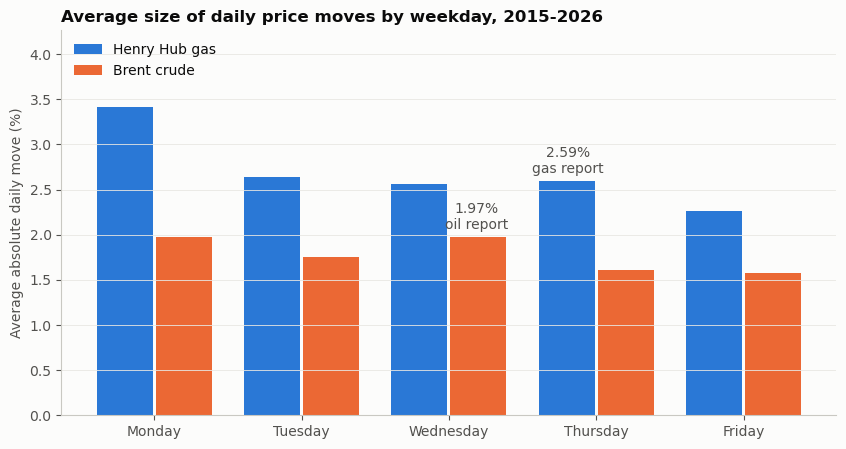

Henry Hub gas-report days 2.59% vs other days 2.71% -> 0.96x  (Mann-Whitney p = 0.7401, n = 527)
Brent     gas-report days 1.61% vs other days 1.81% -> 0.89x  (Mann-Whitney p = 0.9883, n = 527)


In [3]:
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
clean = returns[~is_excluded].copy()
clean["is_report_day"] = clean.index.isin(storage["report_date"])
clean["weekday"] = pd.Categorical(clean.index.day_name(), categories=DAYS, ordered=True)

abs_by_day = clean.groupby("weekday", observed=True)[["henry_hub", "brent"]].agg(lambda x: x.abs().mean() * 100)

x = np.arange(len(DAYS))
w = 0.38
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(x - w / 2 - 0.01, abs_by_day["henry_hub"], w, color=BLUE, label="Henry Hub gas")
ax.bar(x + w / 2 + 0.01, abs_by_day["brent"], w, color=ORANGE, label="Brent crude")
ax.annotate(f"{abs_by_day.loc['Thursday', 'henry_hub']:.2f}%\ngas report",
            (3 - w / 2, abs_by_day.loc["Thursday", "henry_hub"]), xytext=(0, 6),
            textcoords="offset points", ha="center", color=INK2)
ax.annotate(f"{abs_by_day.loc['Wednesday', 'brent']:.2f}%\noil report",
            (2 + w / 2, abs_by_day.loc["Wednesday", "brent"]), xytext=(0, 6),
            textcoords="offset points", ha="center", color=INK2)
ax.set_xticks(x, DAYS)
ax.set_ylabel("Average absolute daily move (%)")
ax.set_title(f"Average size of daily price moves by weekday, {START[:4]}-{clean.index[-1].year}")
ax.set_ylim(0, abs_by_day.values.max() * 1.25)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
save(fig, "05_abs_move_by_weekday")
plt.show()

for col, name in [("henry_hub", "Henry Hub"), ("brent", "Brent")]:
    a = clean[col].abs() * 100
    rep, other = a[clean["is_report_day"]], a[~clean["is_report_day"]]
    p = stats.mannwhitneyu(rep, other, alternative="greater").pvalue
    print(f"{name:9s} gas-report days {rep.mean():.2f}% vs other days {other.mean():.2f}% "
          f"-> {rep.mean() / other.mean():.2f}x  (Mann-Whitney p = {p:.4f}, n = {len(rep)})")

**About the statistical test:** daily commodity returns have *fat tails*: a few huge days dominate the averages. The **Mann-Whitney test** compares the whole distributions, not just the means, so a handful of extreme days can't drive the result on their own. A p-value below 0.05 means a difference this large would be unlikely if Thursdays were no different from other days.

## 3. Does the surprise predict direction?
For each report:
- **Surprise** = actual weekly change minus the average change for the same week over the previous 5 years (Bcf).
- **Reaction** = Henry Hub's Wednesday-close to Thursday-close return.

If the market trades on the surprise, the slope should be **negative**: a smaller injection than normal (negative surprise) should mean price goes up.

**Hit rate** = how often the price moved in the direction the surprise implied. 50% is a coin flip.

**Winter vs summer:** in winter (Nov-Mar) the market worries about running short, so the same Bcf surprise may matter more.

In [4]:
events = storage.loc[START:, ["report_date", "change_bcf", "change_5y_avg", "surprise_bcf"]].dropna()
events = events[events["report_date"].isin(trading_days) & ~events["report_date"].isin(excluded_days)]

pos = trading_days.get_indexer(events["report_date"])
events = events[pos + 3 < len(trading_days)]  # need 3 days after each report for the event study
pos = trading_days.get_indexer(events["report_date"])

events["thu_ret"] = returns["henry_hub"].values[pos] * 100
events["fri_ret"] = returns["henry_hub"].values[pos + 1] * 100
events["season"] = np.where(events["report_date"].dt.month.isin([11, 12, 1, 2, 3]), "Winter (Nov-Mar)", "Summer (Apr-Oct)")


results = pd.DataFrame({
    "All reports": surprise_regression(events),
    **{s: surprise_regression(g) for s, g in events.groupby("season")},
    "Friday (next day)": surprise_regression(events, y="fri_ret"),
}).T
results.round(3)

,n,slope_%_per_10bcf,t_stat,p_value,r2,hit_rate
All reports,524.0,0.002,0.061,0.952,0.000,0.525
Summer (Apr-Oct),314.0,-0.159,-2.164,0.030,0.011,0.540
Winter (Nov-Mar),210.0,0.041,0.946,0.344,0.005,0.502
Friday (next day),524.0,0.011,0.292,0.771,0.000,0.466


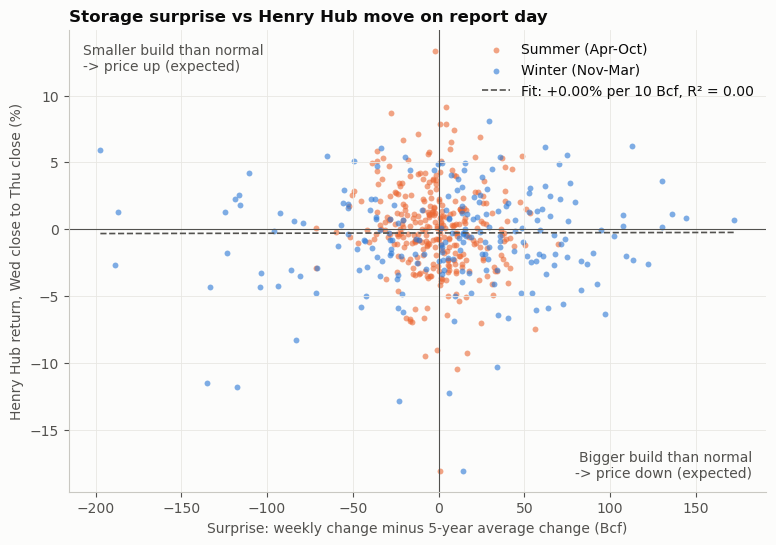

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
for season, color in [("Summer (Apr-Oct)", ORANGE), ("Winter (Nov-Mar)", BLUE)]:
    g = events[events["season"] == season]
    ax.scatter(g["surprise_bcf"], g["thu_ret"], s=18, color=color, alpha=0.6, lw=0, label=season)

fit = sm.OLS(events["thu_ret"], sm.add_constant(events["surprise_bcf"])).fit()
xs = np.linspace(events["surprise_bcf"].min(), events["surprise_bcf"].max(), 50)
ax.plot(xs, fit.params["const"] + fit.params["surprise_bcf"] * xs, color=INK2, ls="--", lw=1.2,
        label=f"Fit: {fit.params['surprise_bcf'] * 10:+.2f}% per 10 Bcf, R² = {fit.rsquared:.2f}")
ax.axhline(0, color=INK2, lw=0.8)
ax.axvline(0, color=INK2, lw=0.8)
ax.text(0.02, 0.97, "Smaller build than normal\n-> price up (expected)", transform=ax.transAxes, va="top", color=INK2)
ax.text(0.98, 0.03, "Bigger build than normal\n-> price down (expected)", transform=ax.transAxes, ha="right", color=INK2)
ax.set_title("Storage surprise vs Henry Hub move on report day")
ax.set_xlabel("Surprise: weekly change minus 5-year average change (Bcf)")
ax.set_ylabel("Henry Hub return, Wed close to Thu close (%)")
ax.legend(loc="upper right")
save(fig, "06_surprise_vs_report_day_return")
plt.show()

## 4. Event study: the average path around the report
This is a standard method in finance research. Line up every report on "day 0" and track the average cumulative price move from 3 trading days before to 3 days after, measured from the close the day before the report.

Reports are grouped by surprise:
- **Bullish:** the 20% of weeks with the smallest change compared with normal.
- **Bearish:** the 20% with the biggest change compared with normal.
- **Neutral:** everything in between.

What to look for:
- **A jump at day 0:** the market reacts to the news.
- **Drift before day 0:** the market saw it coming. Weather forecasts let traders estimate the number in advance.
- **Drift after day 0:** the market under-reacted, or the move reversed.

The shaded bands are 95% confidence intervals. Where they overlap, the groups aren't reliably different.

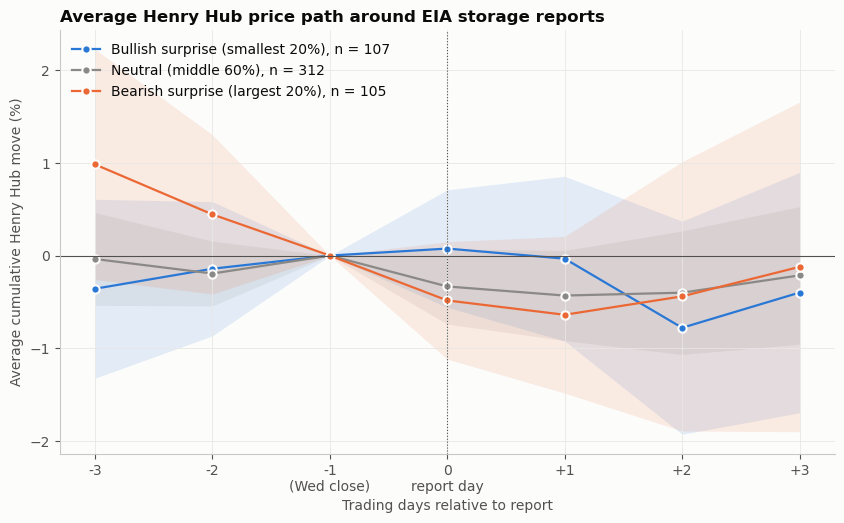

,-3,-2,-1,0,1,2,3
Bullish surprise (smallest 20%),-0.36,-0.14,0.0,0.08,-0.03,-0.78,-0.40
Neutral (middle 60%),-0.04,-0.19,0.0,-0.33,-0.43,-0.40,-0.21
Bearish surprise (largest 20%),0.98,0.44,0.0,-0.48,-0.64,-0.44,-0.12


In [6]:
cum = returns["henry_hub"].where(~is_excluded, 0).cumsum().values  # expiry/roll-day moves removed
offsets = range(-3, 4)
paths = pd.DataFrame({k: (cum[pos + k] - cum[pos - 1]) * 100 for k in offsets}, index=events.index)

quintile = pd.qcut(events["surprise_bcf"], 5, labels=False)
groups = {
    "Bullish surprise (smallest 20%)": (quintile == 0, BLUE),
    "Neutral (middle 60%)": (quintile.between(1, 3), GRAY),
    "Bearish surprise (largest 20%)": (quintile == 4, ORANGE),
}

fig, ax = plt.subplots(figsize=(10, 5.5))
for label, (mask, color) in groups.items():
    g = paths[mask]
    mean, se = g.mean(), g.std() / np.sqrt(len(g))
    ax.fill_between(list(offsets), mean - 1.96 * se, mean + 1.96 * se, color=color, alpha=0.12, lw=0)
    ax.plot(list(offsets), mean, color=color, marker="o", ms=6, mec="#fcfcfb", mew=1.5, label=f"{label}, n = {len(g)}")
ax.axvline(0, color=INK2, lw=0.8, ls=":")
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(list(offsets), ["-3", "-2", "-1\n(Wed close)", "0\nreport day", "+1", "+2", "+3"])
ax.set_xlabel("Trading days relative to report")
ax.set_ylabel("Average cumulative Henry Hub move (%)")
ax.set_title("Average Henry Hub price path around EIA storage reports")
ax.legend(loc="upper left")
save(fig, "07_event_study")
plt.show()

summary = pd.DataFrame({label: paths[mask].mean() for label, (mask, _) in groups.items()}).T.round(2)
summary

## Findings

**1. Daily data can't see the report.** Thursday moves are no bigger than other days (2.59% vs 2.71%, p ≈ 0.74). The biggest day is **Monday** (3.4%), which carries three days of news: weekend weather forecast updates pile up while the market is shut.
- This doesn't mean the report doesn't matter. Studies using minute-by-minute data find a sharp spike in the minutes after 10:30, which settles within the hour.
- Over a full day, changes in weather forecasts swamp the report.
- The Brent control behaves as expected: oil's Wednesday move (1.97%, oil inventory report) is above Tuesday-Friday, though level with Monday.

**2. The 5-year surprise proxy doesn't predict direction.**
- Across all reports, the slope is about zero and the hit rate is 52.5%, barely better than a coin flip.
- Summer shows a small effect in the expected direction (p ≈ 0.03). With four tests run, though, one hit at p < 0.05 is weak evidence.
- Friday shows nothing either: no continuation and no reversal.

**3. The event study suggests why: the market prices the number in advance.** Before bearish reports, prices were already falling: about -1% over the three days before the release. Traders estimate the injection from weather data, so by Thursday the "surprise compared with the 5-year average" is mostly expected. Only the gap between the actual number and the market's forecast moves the price, and free data doesn't include that forecast.

**For trading:**
- Trading a gas CFD on the headline "injection vs 5-year average" isn't an edge.
- The 10:30 release is still a **risk event**. Spreads widen and prices can jump within minutes, so size positions small, or stay flat, around the release.
- An edge would need a **better forecast than the 5-year average**, which is what professional desks build from weather data.

**A possible next step:** build our own injection forecast from free NOAA weather data (heating and cooling degree days), then re-run this notebook with surprise = actual minus our forecast.